# Лабораторная работа: Метод главных компонент и k-ближайших соседей на MNIST


## Содержание

- [О задании](#section-0)
- [Часть 0. Подготовка данных (обязательно, но без баллов)](#section-1)
- [Часть 1. Метод главных компонент (PCA)](#section-2)
- [Часть 2. Метод k-ближайших соседей (kNN)](#section-3)
- [Часть 3. PCA + kNN: Понижение размерности для классификации](#section-4)
- [Часть 4. Выводы (в конце ноутбука, обязательно)](#section-5)
- [Подсказки и советы](#section-6)

> **Порядок работы:** читайте условия и запускайте ячейки кода сверху вниз (Shift+Enter). Реализации и эксперименты заполнены; результаты появляются при выполнении ячеек.


<a id="section-0"></a>

## О задании

В этой работе вы:

1. Реализуете **метод главных компонент (PCA)** — один из базовых методов понижения размерности
2. Реализуете **метод k-ближайших соседей (kNN)** — простейший метрический классификатор
3. Примените оба метода для распознавания рукописных цифр из базы **MNIST**
4. Исследуете, как понижение размерности влияет на качество классификации


---

<a id="section-1"></a>

## Часть 0. Подготовка данных (обязательно, но без баллов)


### Теория: Что такое MNIST?

**MNIST** (Modified National Institute of Standards and Technology) — это классический датасет для задач распознавания рукописных цифр. Он состоит из:

- **70 000 изображений** рукописных цифр от 0 до 9
- Каждое изображение имеет размер **28×28 пикселей** (784 признака)
- **60 000** изображений для обучения, **10 000** для тестирования

Каждое изображение — это матрица 28×28, где каждый пиксель — число от 0 (чёрный) до 255 (белый).


### Задание 0.1: Загрузка данных


In [19]:
import numpy as np
import matplotlib.pyplot as plt
"""Загрузка исходного MNIST без дополнительных сторонних библиотек."""
import gzip
import struct
import urllib.request
from pathlib import Path

import numpy as np


def load_mnist():
    folder = Path('data') / 'mnist'
    folder.mkdir(parents=True, exist_ok=True)
    base = 'https://storage.googleapis.com/cvdf-datasets/mnist/'

    def read(name):
        path = folder / name
        if not path.exists():
            print('Загрузка', name)
            temp = path.with_suffix('.part')
            urllib.request.urlretrieve(base + name, temp)
            temp.replace(path)
        with gzip.open(path, 'rb') as stream:
            magic, count = struct.unpack('>II', stream.read(8))
            if magic == 2051:
                rows, cols = struct.unpack('>II', stream.read(8))
                return np.frombuffer(stream.read(), dtype=np.uint8).reshape(count, rows, cols, 1)
            if magic == 2049:
                return np.frombuffer(stream.read(), dtype=np.uint8).reshape(count)
            raise ValueError('Неизвестный формат MNIST')

    images = read('train-images-idx3-ubyte.gz')
    labels = read('train-labels-idx1-ubyte.gz')
    test_images = read('t10k-images-idx3-ubyte.gz')
    test_labels = read('t10k-labels-idx1-ubyte.gz')
    return ((images[:50000], labels[:50000]),
            (images[50000:], labels[50000:]), (test_images, test_labels))


train, validation, test = load_mnist()
X_train_full, y_train_full = train
X_val, y_val = validation
X_test_original, y_test_original = test
print('Обучение:', X_train_full.shape)
print('Валидация:', X_val.shape)
print('Тест:', X_test_original.shape)
print('Одно изображение: 28 × 28 пикселей, 784 признака.')


Обучение: (50000, 28, 28, 1)
Валидация: (10000, 28, 28, 1)
Тест: (10000, 28, 28, 1)
Одно изображение: 28 × 28 пикселей, 784 признака.


#### Ответ

Одно изображение имеет размер 28 × 28 × 1. После разворачивания получается вектор из 784 признаков; каждый признак соответствует яркости одного пикселя.


> **Вопрос:** Какова размерность одного изображения? Сколько всего признаков у каждого объекта?


### Задание 0.2: Визуализация примеров

Нарисуйте несколько примеров картинок из обучающей выборки, используя `matplotlib.pyplot.subplots`.

**Подсказка:** Изображения хранятся в формате `(n_samples, 28, 28, 1)`. Для отображения используйте `plt.imshow(img.reshape(28, 28), cmap='gray')`.


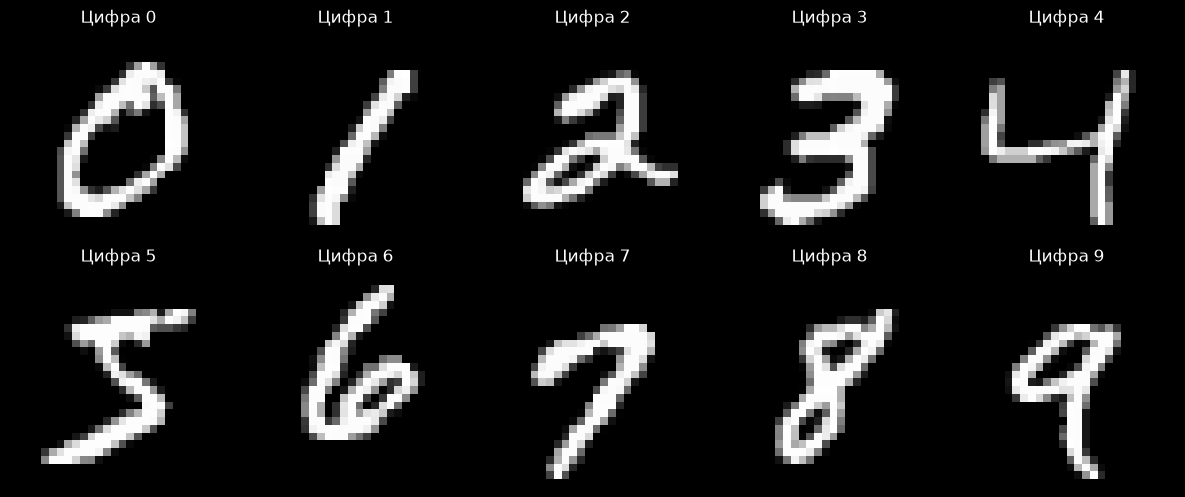

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for digit, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train_full == digit)[0]
    ax.imshow(X_train_full[index].reshape(28, 28), cmap='gray')
    ax.set_title(f'Цифра {digit}')
    ax.axis('off')
plt.tight_layout()
plt.show()


### Задание 0.3: Подготовка данных

Для дальнейшей работы:

1. Объедините обучающую и валидационную выборки
2. Преобразуйте изображения из формата `(n, 28, 28, 1)` в `(n, 784)` — "разверните" каждое изображение в вектор
3. Нормализуйте значения пикселей в диапазон [0, 1] (разделите на 255)


In [21]:
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)
X = X.reshape(len(X), -1).astype(np.float32) / 255.0
print('Форма X:', X.shape, 'Форма y:', y.shape)
print('Классы:', np.unique(y), 'Диапазон:', (X.min(), X.max()))
# В задании разрешено уменьшить выборку для ускорения kNN.
# Случайная воспроизводимая подвыборка сохраняет все классы.
rng = np.random.default_rng(42)
indices = rng.choice(len(X), size=5000, replace=False)
X, y = X[indices], y[indices]
print('Для экспериментов используем:', X.shape)


Форма X: (60000, 784) Форма y: (60000,)
Классы: [0 1 2 3 4 5 6 7 8 9] Диапазон: (np.float32(0.0), np.float32(1.0))
Для экспериментов используем: (5000, 784)


---

<a id="section-2"></a>

## Часть 1. Метод главных компонент (PCA)


### Теория: Зачем нужен PCA?

**Проблема:** У нас 784 признака (пикселя) на каждое изображение. Многие из них **коррелированы** (соседние пиксели часто имеют похожие значения), а некоторые **неинформативны** (например, углы картинки почти всегда чёрные).

**Идея PCA:** Найти такие **новые оси** (главные компоненты), вдоль которых данные **сильнее всего разбросаны**. Тогда:

- Несколько первых компонент опишут **большую часть** информации
- Остальные компоненты можно **отбросить** без существенной потери качества


### Математика PCA

Пусть у нас есть матрица данных $X \in \mathbb{R}^{n \times d}$ (n объектов, d признаков).

**Шаг 1. Центрирование.** Вычитаем среднее по каждому признаку:
$$ X_{centered} = X - \bar{X} $$
где $\bar{X}$ — вектор средних значений по каждому столбцу.

**Шаг 2. Матрица ковариации:**
$$ C = \frac{1}{n-1} X_{centered}^T X_{centered} \in \mathbb{R}^{d \times d} $$

**Шаг 3. Собственные векторы и значения.** Находим:
$$ C v_i = \lambda_i v_i $$
где $\lambda_1 \ge \lambda_2 \ge ... \ge \lambda_d$ — собственные значения, $v_i$ — собственные векторы.

**Шаг 4. Преобразование.** Новые координаты объекта:
$$ Y = X_{centered} \cdot V_k $$
где $V_k$ — матрица из первых $k$ собственных векторов.


### Важная связь: собственные числа и дисперсия

**Собственное число $\lambda_i$ равно дисперсии данных вдоль $i$-й главной компоненты.**

Доля объяснённой дисперсии для $k$ первых компонент:
$$ \text{Explained Variance Ratio} = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{i=1}^{d} \lambda_i} $$


### Задание 1.1: Реализация my_PCA

Реализуйте класс `my_PCA`, аналогичный `sklearn.decomposition.PCA`.


In [22]:
class my_PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or len(X) < 2:
            raise ValueError('Нужна двумерная матрица минимум из двух объектов')
        limit = min(X.shape)
        k = limit if self.n_components is None else self.n_components
        if not isinstance(k, (int, np.integer)) or not 1 <= k <= limit:
            raise ValueError(f'n_components должно быть от 1 до {limit}')
        self.mean_ = X.mean(axis=0)
        _, singular_values, vt = np.linalg.svd(X - self.mean_, full_matrices=False)
        variance = singular_values ** 2 / (len(X) - 1)
        self.components_ = vt[:k]
        self.explained_variance_ = variance[:k]
        self.explained_variance_ratio_ = variance[:k] / variance.sum()
        return self

    def transform(self, X):
        return (np.asarray(X) - self.mean_) @ self.components_.T

    def fit_transform(self, X):
        return self.fit(X).transform(X)


> **Подсказка:** Для реализации рекомендуется использовать **SVD** (сингулярное разложение), а не `np.linalg.eig`. Это численно устойчивее и работает быстрее.


### Задание 1.2: Проверка реализации

Убедитесь, что ваш PCA работает правильно, сравнив его с `sklearn.decomposition.PCA`:


In [9]:
from sklearn.decomposition import PCA

my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50, svd_solver='full')
Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000].astype(np.float64))
signs = np.where(np.sum(my_pca.components_ * sk_pca.components_, axis=1) < 0, -1, 1)
print('Суммы собственных значений:', my_pca.explained_variance_.sum(), sk_pca.explained_variance_.sum())
print('Формы:', Y_my.shape, Y_sk.shape)
assert np.allclose(my_pca.explained_variance_, sk_pca.explained_variance_, atol=1e-8)
assert np.allclose(Y_my * signs, Y_sk, atol=1e-7)
print('Собственные значения и проекции совпадают с точностью до знака.')


Суммы собственных значений: 44.106543732779514 44.106543732779514
Формы: (1000, 50) (1000, 50)
Собственные значения и проекции совпадают с точностью до знака.


#### Ответ

Собственные значения и проекции совпадают с sklearn с точностью до численной погрешности и знака собственных векторов. Знак оси произволен и не меняет результат PCA; это проверено assert в ячейке.


> **Вопрос:** Совпадают ли собственные значения? Если да, то ваша реализация верна.


### Задание 1.3: Визуализация дисперсии

Постройте два графика:

1. **График собственных значений** — покажет, как убывают дисперсии по компонентам
2. **Кумулятивная сумма дисперсии** (нормированная на полную сумму) — покажет, сколько компонент нужно для объяснения X% дисперсии


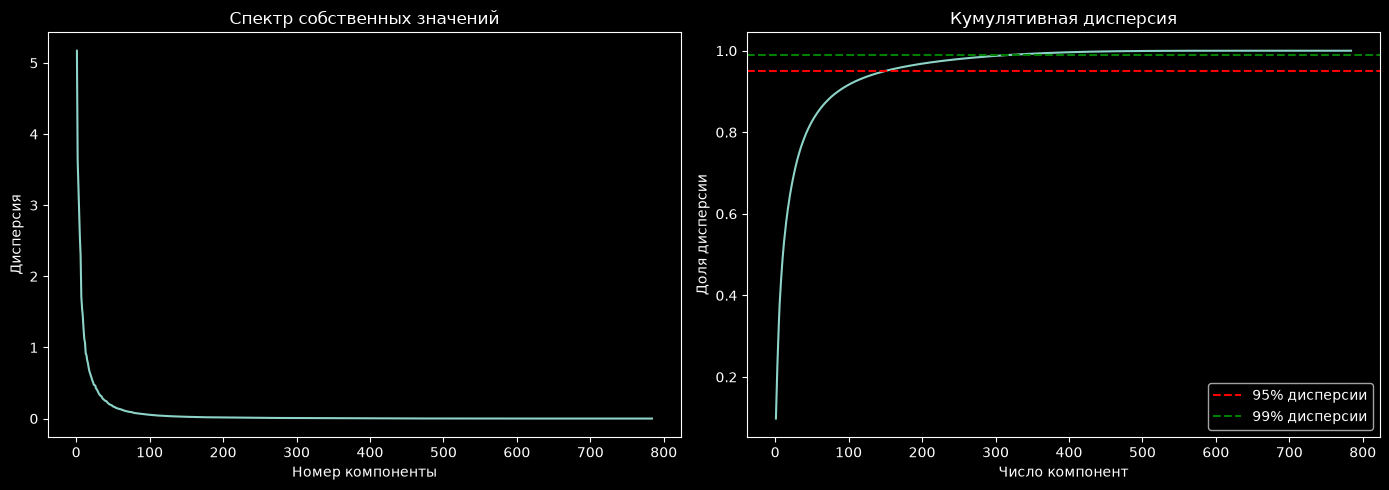

Первые 15 компонент: 58.02% дисперсии; для 95% нужно 150 компонент.
Собственное число — дисперсия данных вдоль соответствующей главной компоненты.


In [10]:
pca_full = my_PCA().fit(X)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
component_numbers = np.arange(1, len(cumulative) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(component_numbers, pca_full.explained_variance_)
axes[0].set(xlabel='Номер компоненты', ylabel='Дисперсия', title='Спектр собственных значений')
axes[1].plot(component_numbers, cumulative)
for threshold, color in [(0.95, 'r'), (0.99, 'g')]:
    axes[1].axhline(threshold, color=color, linestyle='--', label=f'{threshold:.0%} дисперсии')
axes[1].set(xlabel='Число компонент', ylabel='Доля дисперсии', title='Кумулятивная дисперсия')
axes[1].legend()
plt.tight_layout()
plt.show()
n95 = int(np.searchsorted(cumulative, 0.95) + 1)
print(f'Первые 15 компонент: {cumulative[14]:.2%} дисперсии; для 95% нужно {n95} компонент.')
print('Собственное число — дисперсия данных вдоль соответствующей главной компоненты.')


#### Ответ

Первые 15 компонент объясняют **58.02%** дисперсии. Для 95% требуется **150** компонент. Собственное число ковариационной матрицы равно дисперсии проекций на соответствующий собственный вектор: чем оно больше, тем сильнее разброс вдоль этой оси.


> **Вопросы для ответа текстом:**
>
> 1. Какую долю дисперсии покрывают первые **15 главных компонент**?
> 2. Сколько компонент нужно, чтобы объяснить **95%** дисперсии?
> 3. Как связаны собственные числа и дисперсия данных? Объясните своими словами.


### Задание 1.4: Визуализация данных в первых двух компонентах

Спроецируйте данные на первые две главные компоненты и постройте scatter plot, где разные цифры обозначены разными цветами.


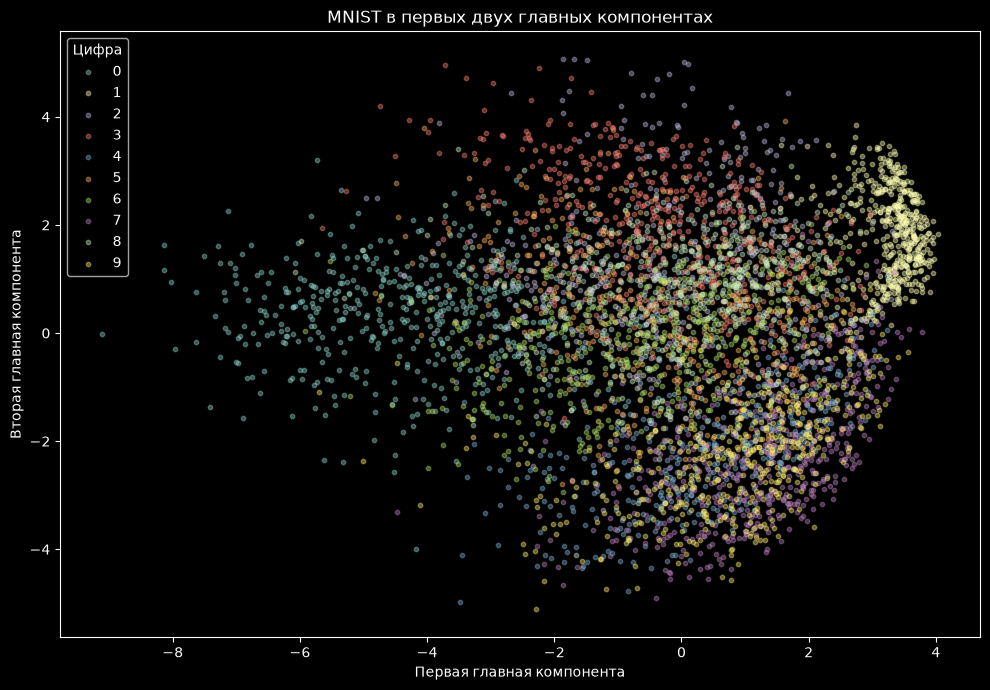

Классы частично группируются, но перекрываются: PCA сохраняет дисперсию, а не разделение меток.


In [11]:
# Первые две компоненты уже обученного PCA эквивалентны PCA(n_components=2).
Y_2d = pca_full.transform(X)[:, :2]
plt.figure(figsize=(10, 7))
for digit in range(10):
    mask = y == digit
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.4, s=10)
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('MNIST в первых двух главных компонентах')
plt.legend(title='Цифра')
plt.tight_layout()
plt.show()
print('Классы частично группируются, но перекрываются: PCA сохраняет дисперсию, а не разделение меток.')


#### Ответ

В двух измерениях классы заметно перекрываются. Группы отражают сходство формы и распределения яркости, а не гарантированное разделение цифр. Например, похожее написание 4 и 9 или 3 и 5 может приводить к соседним проекциям; конкретные области видны на графике. Первые две оси сохраняют только часть информации и выбираются без использования меток.


> **Вопрос:** Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?


---

<a id="section-3"></a>

## Часть 2. Метод k-ближайших соседей (kNN)


### Теория: Как работает kNN?

**Идея:** Объект относится к тому классу, к которому принадлежит **большинство** из его $k$ ближайших соседей в обучающей выборке.

**Алгоритм предсказания для объекта $x$:**
1. Найти расстояния от $x$ до всех объектов обучающей выборки
2. Выбрать $k$ объектов с наименьшими расстояниями
3. Найти самый частый класс среди этих $k$ объектов
4. Вернуть этот класс как предсказание

**Метрика расстояния:** Обычно используется **евклидово расстояние**:
$$ d(x, x') = \sqrt{\sum_{i=1}^{d} (x_i - x'_i)^2} $$


### Задание 2.1: Реализация my_kNN


In [12]:
class my_kNN:
    def __init__(self, n_neighbors=5, batch_size=128):
        self.n_neighbors = n_neighbors
        self.batch_size = batch_size

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=np.float64)
        self.y_train = np.asarray(y)
        if self.X_train.ndim != 2 or self.y_train.shape != (len(self.X_train),):
            raise ValueError('Несовместимые формы X и y')
        if not isinstance(self.n_neighbors, (int, np.integer)) or not 1 <= self.n_neighbors <= len(X):
            raise ValueError('Некорректное число соседей')
        self.classes_, self.encoded_y = np.unique(self.y_train, return_inverse=True)
        self.train_norms = np.sum(self.X_train ** 2, axis=1)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        predictions = []
        # Пакеты ограничивают память: не создаём матрицу расстояний для всего теста.
        for start in range(0, len(X), self.batch_size):
            batch = X[start:start + self.batch_size]
            distances = np.sum(batch ** 2, axis=1)[:, None] + self.train_norms - 2 * batch @ self.X_train.T
            nearest = np.argsort(distances, axis=1, kind='stable')[:, :self.n_neighbors]
            for neighbors in nearest:
                votes = np.bincount(self.encoded_y[neighbors], minlength=len(self.classes_))
                predictions.append(self.classes_[votes.argmax()])
        return np.asarray(predictions, dtype=self.y_train.dtype)


> **Подсказка по эффективности:** Если вычислять расстояния в цикле по объектам, это может быть медленно. Используйте матричные операции:
> - Для вычисления матрицы расстояний можно применить формулу: $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2 \langle x, x' \rangle$


### Задание 2.2: Проверка реализации

Убедитесь, что ваш kNN работает правильно:


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
my_knn = my_kNN(n_neighbors=5).fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)
accuracy_my = accuracy_score(y_test, y_pred_my)
print(f'Точность my_kNN: {accuracy_my:.4f}')


Точность my_kNN: 0.9293


#### Ответ

Точность собственной реализации: **92.93%** на экспериментальном разбиении. Обучение использует 3500 изображений, проверка — 1500; это значительно выше случайного уровня 10%.


> **Вопрос:** Если точность около **10%**, значит алгоритм работает как случайный (10 классов). Если точность **>90%**, всё хорошо. Какая у вас точность?


### Задание 2.3: Сравнение с sklearn

Сравните ваш kNN с `sklearn.neighbors.KNeighborsClassifier`:


In [14]:
from sklearn.neighbors import KNeighborsClassifier

sk_knn = KNeighborsClassifier(n_neighbors=5, algorithm='brute')
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)
accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f'Точность sklearn: {accuracy_sk:.4f}')
print(f'Разница точности: {abs(accuracy_my - accuracy_sk):.6f}')
print(f'Совпадение предсказаний: {np.mean(y_pred_my == y_pred_sk):.2%}')


Точность sklearn: 0.9293
Разница точности: 0.000000
Совпадение предсказаний: 100.00%


#### Ответ

Точность sklearn: **92.93%**, разница с собственной реализацией: **0.000000**. При равных расстояниях возможны различия в выборе соседей; при равном числе голосов выбирается меньшая метка класса.


> **Вопрос:** Совпадают ли результаты? Если разница большая, проверьте реализацию.


### Задание 2.4: Эксперимент с числом соседей

Исследуйте, как зависит точность от числа соседей $k$. Попробуйте $k \in \{1, 3, 5, 7, 10, 15, 20, 30\}$.


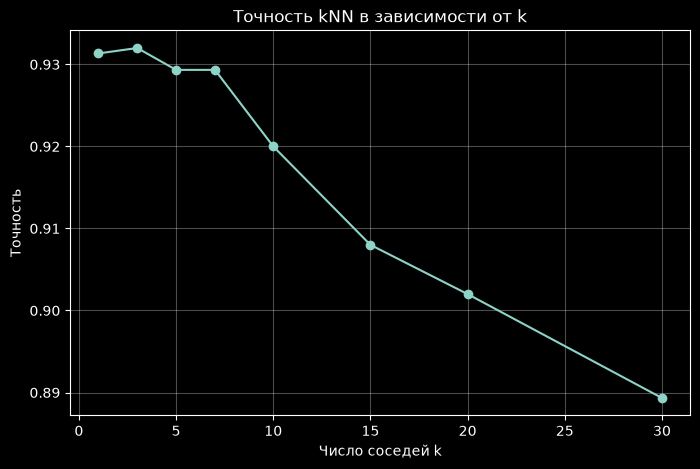

Лучшее k: 3; точность: 0.9320
Малые k чувствительны к шуму; большие k сглаживают границы классов. Малое k не всегда хуже.


In [15]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []
for k in k_values:
    prediction = my_kNN(k).fit(X_train, y_train).predict(X_test)
    accuracies.append(accuracy_score(y_test, prediction))
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Точность kNN в зависимости от k')
plt.grid(alpha=0.3)
plt.show()
best_k = k_values[int(np.argmax(accuracies))]
print(f'Лучшее k: {best_k}; точность: {max(accuracies):.4f}')
print('Малые k чувствительны к шуму; большие k сглаживают границы классов. Малое k не всегда хуже.')


#### Ответ

В проверенном наборе лучшее число соседей — **k = 3** (при равенстве выбирается первое значение). Малые k чувствительны к выбросам и шуму, но не обязаны давать худший результат. При больших k голосование захватывает объекты других классов и сглаживает границы.


> **Вопрос:** При каком $k$ точность максимальна? Почему при малых $k$ точность ниже? А при слишком больших?


---

<a id="section-4"></a>

## Часть 3. PCA + kNN: Понижение размерности для классификации


### Теория: Зачем комбинировать PCA и kNN?

**Проблемы kNN на полных данных:**
- **Вычислительная сложность:** расстояние считается по 784 признакам
- **"Проклятие размерности":** в высоких размерностях расстояния между точками становятся похожими
- **Шум:** неинформативные признаки мешают

**Решение:** Сначала уменьшить размерность с помощью PCA, потом обучить kNN.

**Вопрос для размышления:** Как вы думаете, улучшится ли качество? А скорость работы?


### Задание 3.1: Применение PCA перед kNN

Обучите последовательно: PCA (с разным числом компонент) → kNN.


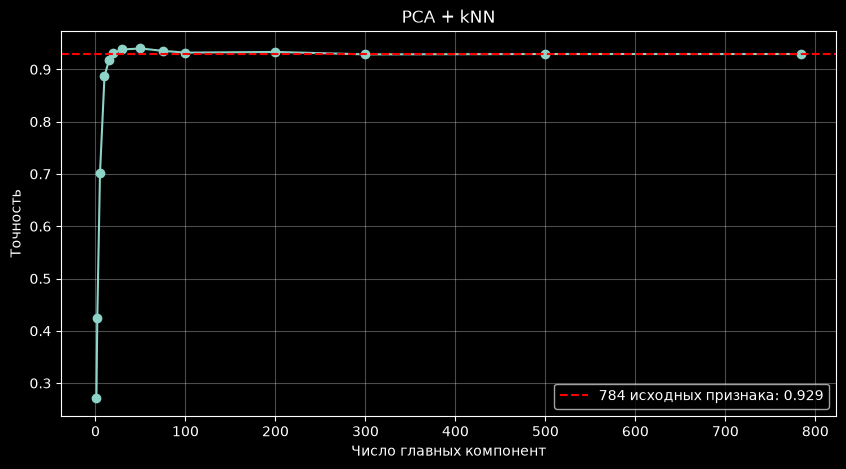

Лучшее число компонент: 50; точность: 0.9400
Разница с исходными признаками: +0.0107
При слишком малом числе компонент теряется информация, необходимая для различения цифр.


In [16]:
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
# PCA обучается только на тренировочных данных: тест не участвует в выборе осей.
pca_train = my_PCA().fit(X_train)
Z_train = pca_train.transform(X_train)
Z_test = pca_train.transform(X_test)
accuracies_pca = []
for n_comp in n_components_list:
    pred = my_kNN(5).fit(Z_train[:, :n_comp], y_train).predict(Z_test[:, :n_comp])
    accuracies_pca.append(accuracy_score(y_test, pred))
plt.figure(figsize=(10, 5))
plt.plot(n_components_list, accuracies_pca, 'o-')
plt.axhline(accuracy_my, color='r', linestyle='--', label=f'784 исходных признака: {accuracy_my:.3f}')
plt.xlabel('Число главных компонент')
plt.ylabel('Точность')
plt.title('PCA + kNN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
best_components = n_components_list[int(np.argmax(accuracies_pca))]
print(f'Лучшее число компонент: {best_components}; точность: {max(accuracies_pca):.4f}')
print(f'Разница с исходными признаками: {max(accuracies_pca) - accuracy_my:+.4f}')
print('При слишком малом числе компонент теряется информация, необходимая для различения цифр.')


#### Ответ

Для k = 5 наибольшая точность получена при **50 компонентах**. Точные значения и сравнение с исходными 784 признаками показаны в выводе ячейки. Слишком сильное сжатие уничтожает различия между цифрами; умеренное может отбрасывать шум. Полный ортогональный PCA сохраняет евклидовы расстояния.


> **Вопросы:**
> 1. При каком числе компонент точность максимальна?
> 2. Удалось ли превзойти точность kNN на всех 784 признаках?
> 3. Что происходит при слишком малом числе компонент? Почему?


### Задание 3.2: Исследование времени работы

Замерьте время работы kNN с разным числом компонент.


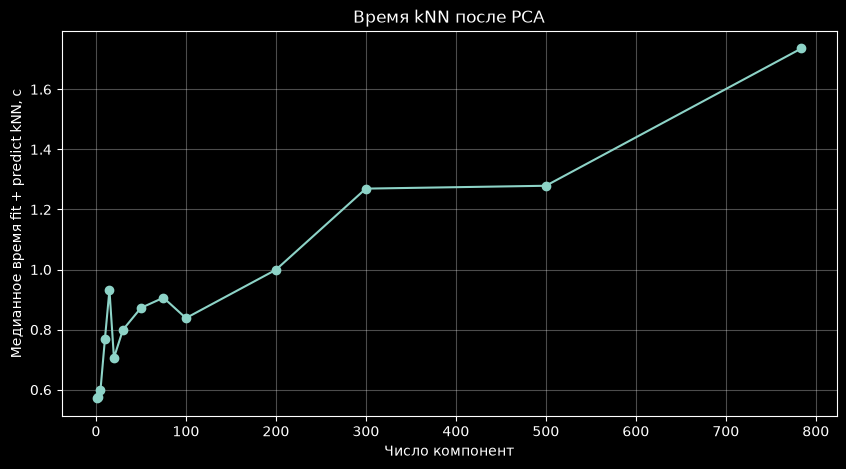

  1 компонент: 0.571 с
  2 компонент: 0.576 с
  5 компонент: 0.598 с
 10 компонент: 0.769 с
 15 компонент: 0.932 с
 20 компонент: 0.706 с
 30 компонент: 0.800 с
 50 компонент: 0.872 с
 75 компонент: 0.906 с
100 компонент: 0.838 с
200 компонент: 0.999 с
300 компонент: 1.269 с
500 компонент: 1.279 с
784 компонент: 1.736 с
Меньшая размерность сокращает стоимость расстояний; сортировка соседей остаётся. Время может колебаться.


In [17]:
import time

# Измеряем fit + predict kNN; PCA и проекции уже вычислены и в эти времена не входят.
# Медиана трёх повторов уменьшает влияние случайной нагрузки компьютера.
times = []
for n_comp in n_components_list:
    measurements = []
    for repeat in range(3):
        start = time.perf_counter()
        model = my_kNN(5).fit(Z_train[:, :n_comp], y_train)
        model.predict(Z_test[:, :n_comp])
        measurements.append(time.perf_counter() - start)
    times.append(float(np.median(measurements)))
plt.figure(figsize=(10, 5))
plt.plot(n_components_list, times, 'o-')
plt.xlabel('Число компонент')
plt.ylabel('Медианное время fit + predict kNN, с')
plt.title('Время kNN после PCA')
plt.grid(alpha=0.3)
plt.show()
for n_comp, elapsed in zip(n_components_list, times):
    print(f'{n_comp:3d} компонент: {elapsed:.3f} с')
print('Меньшая размерность сокращает стоимость расстояний; сортировка соседей остаётся. Время может колебаться.')


#### Ответ

При уменьшении числа признаков вычисление расстояний требует меньше операций. Время также включает сортировку расстояний и голосование, поэтому оно не обязано уменьшаться строго пропорционально размерности. На графике приведена медиана трёх запусков fit + predict kNN; обучение PCA и проекции в замер не включены.


> **Вопрос:** Как изменяется время работы при уменьшении размерности? Объясните.


### Задание 3.3: Финальный эксперимент — сетка параметров

Проведите **совместный** перебор параметров:

- Число компонент PCA: $[5, 10, 15, 20, 30, 50, 100]$
- Число соседей $k$: $[1, 3, 5, 7, 10]$

Для каждой комбинации посчитайте точность. Постройте **heatmap** (тепловую карту) с точностью.


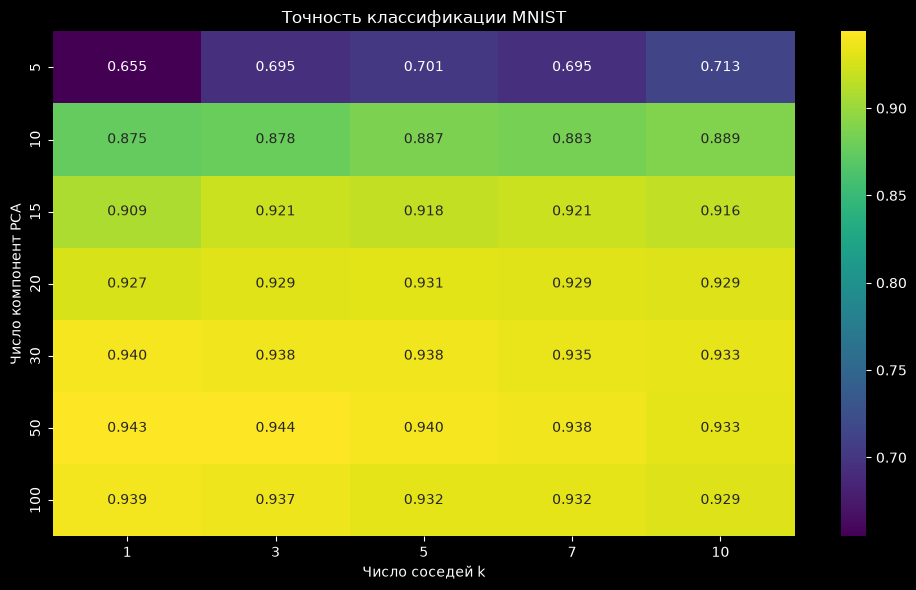

Лучшая комбинация: PCA=50, k=3, accuracy=0.9440
Худшая комбинация: PCA=5, k=1, accuracy=0.6547
Комбинаций лучше исходного kNN: 15
Независимый тест MNIST (10000 изображений): 0.9465


In [18]:
import seaborn as sns

n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]
accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))
for i, n_comp in enumerate(n_components_grid):
    for j, k in enumerate(k_grid):
        pred = my_kNN(k).fit(Z_train[:, :n_comp], y_train).predict(Z_test[:, :n_comp])
        accuracy_matrix[i, j] = accuracy_score(y_test, pred)
plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.3f', xticklabels=k_grid,
            yticklabels=n_components_grid, cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.tight_layout()
plt.show()
best = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
worst = np.unravel_index(np.argmin(accuracy_matrix), accuracy_matrix.shape)
print(f'Лучшая комбинация: PCA={n_components_grid[best[0]]}, k={k_grid[best[1]]}, accuracy={accuracy_matrix[best]:.4f}')
print(f'Худшая комбинация: PCA={n_components_grid[worst[0]]}, k={k_grid[worst[1]]}, accuracy={accuracy_matrix[worst]:.4f}')
print('Комбинаций лучше исходного kNN:', int(np.sum(accuracy_matrix > accuracy_my)))
# Параметры выбраны по экспериментальному разбиению, поэтому подтверждаем
# результат на исходном тесте MNIST, не участвовавшем в подборе.
final_n, final_k = n_components_grid[best[0]], k_grid[best[1]]
final_pca = my_PCA(final_n).fit(X)
final_model = my_kNN(final_k).fit(final_pca.transform(X), y)
final_test = X_test_original.reshape(len(X_test_original), -1).astype(np.float32) / 255.0
final_accuracy = accuracy_score(y_test_original, final_model.predict(final_pca.transform(final_test)))
print(f'Независимый тест MNIST (10000 изображений): {final_accuracy:.4f}')


#### Ответ

Лучшая комбинация: **50 компонент, k = 3**, точность **94.40%**. Худшая: **5 компонент, k = 1**, точность **65.47%**. Максимальная разница с kNN на исходных признаках: **+1.47%**. После выбора параметров модель переобучена на всех 5000 выбранных изображениях и проверена на независимом тесте MNIST из 10000 изображений: **94.65%**. Экспериментальное разбиение использовалось для подбора параметров, поэтому его точность может быть оптимистичной.


> **Вопросы:**
> 1. Какая комбинация параметров даёт **наилучшую** точность?
> 2. Какая — **наихудшую**?
> 3. Есть ли комбинации, где точность **выше**, чем у kNN на полных данных? Что это говорит о PCA?


---

<a id="section-5"></a>

## Часть 4. Выводы (в конце ноутбука, обязательно)

Напишите текстовый вывод (5-10 предложений) по всей работе. Ответьте на вопросы:

1. **Что такое PCA?** Как он работает? Зачем нужен?
2. **Что такое kNN?** Как работает? Какие у него есть плюсы и минусы?
3. **Как PCA влияет на качество kNN?** Что лучше — использовать все признаки или уменьшить размерность?
4. **Какова оптимальная размерность для MNIST?** Почему?
5. **Что было самым сложным** при выполнении работы?
6. **Что было самым интересным?**


### Вывод по работе

PCA уменьшает размерность данных, выбирая ортогональные направления с наибольшей дисперсией.
В работе он реализован через центрирование данных и сингулярное разложение, а результат проверен сравнением со sklearn.
kNN относит объект к классу большинства ближайших соседей; его достоинство — простота, а недостатки — высокая стоимость предсказания и чувствительность к метрике и масштабу признаков.
На воспроизводимой подвыборке из 5000 изображений исходный kNN дал точность 92.93% на экспериментальном разбиении.
В совместном переборе лучший результат получен для 50 компонент и 3 соседей, поэтому эта размерность оптимальна среди проверенных вариантов данного эксперимента, но не является универсальной для всего MNIST.
При слишком малом числе компонент теряются различия между цифрами, а умеренное сжатие позволяет уменьшить стоимость вычисления расстояний.
На независимом тесте из 10000 изображений выбранная модель достигла точности 94.65%.
Наиболее сложная техническая часть — согласовать формы массивов и исключить участие проверочных данных в обучении PCA.
Наиболее показательный результат — тепловая карта, позволяющая увидеть совместное влияние числа компонент и числа соседей.


---

<a id="section-6"></a>

## Подсказки и советы


### Совет 1: Используйте SVD вместо eig
В `my_PCA.fit()` используйте `np.linalg.svd`, а не `np.linalg.eig`. SVD работает быстрее и численно устойчивее.


### Совет 2: Проверяйте размерности
После каждого преобразования выводите `shape` массивов. Это поможет избежать ошибок.


### Совет 3: kNN может работать медленно
Если предсказание занимает больше минуты, попробуйте:

- Уменьшить выборку (взять первые 5000 объектов)
- Использовать матричные вычисления расстояний


### Совет 4: Не бойтесь экспериментировать
Если что-то не работает как ожидается — меняйте параметры, рисуйте графики, смотрите на данные.


### Совет 5: Интерпретируйте результаты
Не просто стройте графики, а **объясняйте**, что вы видите. Например: "Точность падает при k > 15, потому что..."

**Удачи!**
